# 03 · Drift experiments — static vs periodic vs drift-aware

Reads the experiment database produced by `python -m sentinelml.cli pipeline`.

In [1]:
import matplotlib.pyplot as plt

from sentinelml.common.config import get_settings
from sentinelml.storage.database import Database

s = get_settings()
db = Database(s.db_path)
exp = db.latest_experiment_id()
runs = db.query_df("SELECT * FROM runs WHERE experiment_id=?", (exp,))
runs.groupby(["drift_type", "policy"])[["post_drift_auc", "n_retrains", "detection_delay"]].mean().round(3)

post_drift_auc  n_retrains  detection_delay
drift_type  policy                                                  
gradual     drift_aware           0.933         6.0            450.0
            periodic              0.904         6.0            600.0
            static                0.727         0.0            450.0
incremental drift_aware           0.942         4.4            400.0
            periodic              0.913         6.0            450.0
            static                0.737         0.0            400.0
recurring   drift_aware           0.819         6.0              0.0
            periodic              0.743         6.0              0.0
            static                0.815         0.0              0.0
sudden      drift_aware           0.945         1.0              0.0
            periodic              0.901         6.0              0.0
            static                0.709         0.0              0.0

## AUC trajectories — sudden drift

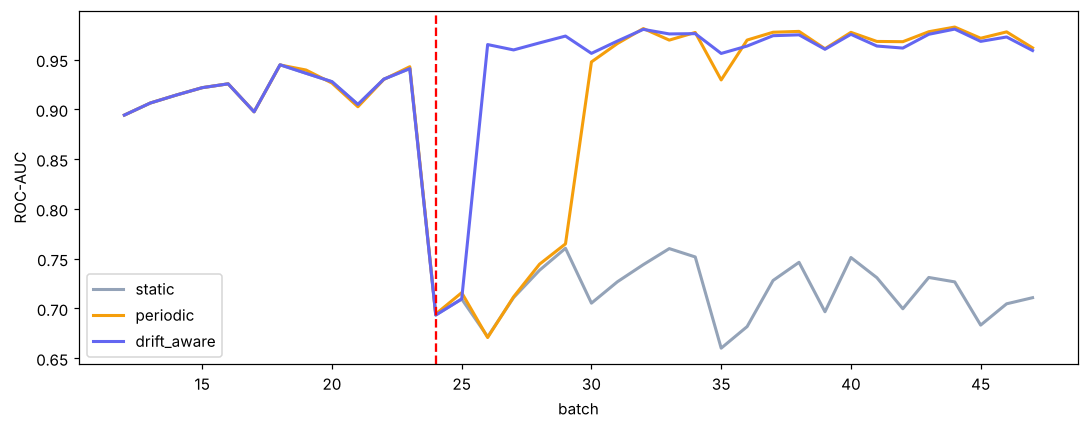

In [2]:
colors = {"static": "#94a3b8", "periodic": "#f59e0b", "drift_aware": "#6366f1"}
fig, ax = plt.subplots(figsize=(10, 4))
for r in runs[(runs.drift_type == "sudden") & (runs.seed == runs.seed.min())].itertuples():
    bm = db.query_df("SELECT batch_id, roc_auc FROM batch_metrics WHERE run_id=?", (r.id,))
    ax.plot(bm.batch_id, bm.roc_auc, label=r.policy, color=colors[r.policy], lw=2)
ax.axvline(24, ls="--", c="r")
ax.set(xlabel="batch", ylabel="ROC-AUC")
ax.legend()
plt.tight_layout()

## Findings
* **Sudden / gradual / incremental:** drift-aware retraining gives the highest post-drift AUC; under
  sudden drift it needs only one validated promotion versus six scheduled retrains.
* **Recurring:** the old concept returns, so the static model is competitive and periodic retraining
  *hurts* — it keeps fitting the concept that is about to disappear. This is reported, not hidden.
* Quality-faulted batches did not produce false drift alarms (quality gate, H3).